# Nepal Earthquake Damage
## Reproducible Data Preprocessing and Exploratory Data Analysis

**Purpose.** Prepare the DrivenData Nepal earthquake building dataset for multiclass damage-grade prediction. The notebook preserves `building_id` for traceability and submission, while excluding it from model features. It reads only the project-relative `raw_data/` directory and never modifies source CSV files.

## tl;dr

- The four raw files contain no missing cells or exact duplicate rows.
- Training labels are imbalanced: Grade 2 is the largest class (56.9%), followed by Grade 3 (33.5%) and Grade 1 (9.6%).
- Geographic IDs are treated as categorical labels, not continuous quantities.
- Six transparent engineered features are created, including an explicit indicator for the unusual `age = 995` value.
- An 80/20 stratified train-validation split is saved with `random_state = 42`.

## 1. Setup and paths

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

PROJECT_DIR = Path.cwd()

# If VS Code/Jupyter starts from the repository root,
# move into the preprocessing folder automatically.
if (PROJECT_DIR / "Preprocess & EDA").exists():
    PROJECT_DIR = PROJECT_DIR / "Preprocess & EDA"

RAW_DATA_DIR = PROJECT_DIR / "raw_data"
PROCESSED_DIR = PROJECT_DIR / "processed_data"
FIGURE_DIR = PROJECT_DIR / "figures"

for directory in (PROCESSED_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
VALIDATION_SIZE = 0.20
DAMAGE_ORDER = [1, 2, 3]
GRADE_COLORS = {1: "#4C78A8", 2: "#F2A541", 3: "#D4504C"}
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)

assert RAW_DATA_DIR.exists(), f"Expected raw_data directory at {RAW_DATA_DIR}"
print(f"Project directory: {PROJECT_DIR}")
print(f"Raw data directory: {RAW_DATA_DIR}")

Project directory: c:\Users\Welkin\OneDrive - HKUST Connect\Desktop\NTU_academic\semester1\6810\group_project\Preprocess & EDA
Raw data directory: c:\Users\Welkin\OneDrive - HKUST Connect\Desktop\NTU_academic\semester1\6810\group_project\Preprocess & EDA\raw_data


## 2. Load raw data

The raw files remain unchanged. All transformations below use copied DataFrames and are saved only to `notebook_outputs/`.

In [2]:
train_values = pd.read_csv(RAW_DATA_DIR / "train_values.csv")
train_labels = pd.read_csv(RAW_DATA_DIR / "train_labels.csv")
test_values = pd.read_csv(RAW_DATA_DIR / "test_values.csv")
submission_format = pd.read_csv(RAW_DATA_DIR / "submission_format.csv")

frames = {
    "train_values": train_values,
    "train_labels": train_labels,
    "test_values": test_values,
    "submission_format": submission_format,
}
{name: frame.shape for name, frame in frames.items()}

{'train_values': (260601, 39),
 'train_labels': (260601, 2),
 'test_values': (86868, 39),
 'submission_format': (86868, 2)}

## 3. Validate source tables

In [3]:
quality_summary = pd.DataFrame({
    "rows": {name: len(frame) for name, frame in frames.items()},
    "columns": {name: frame.shape[1] for name, frame in frames.items()},
    "missing_cells": {name: int(frame.isna().sum().sum()) for name, frame in frames.items()},
    "exact_duplicate_rows": {name: int(frame.duplicated().sum()) for name, frame in frames.items()},
    "building_id_unique": {name: frame["building_id"].is_unique for name, frame in frames.items()},
})

train_label_ids_match = set(train_values["building_id"]) == set(train_labels["building_id"])
test_submission_ids_match = set(test_values["building_id"]) == set(submission_format["building_id"])
train_test_schema_match = list(train_values.columns) == list(test_values.columns)

assert train_label_ids_match
assert test_submission_ids_match
assert train_test_schema_match
quality_summary

,rows,columns,missing_cells,exact_duplicate_rows,building_id_unique
train_values,260601,39,0,0,True
train_labels,260601,2,0,0,True
test_values,86868,39,0,0,True
submission_format,86868,2,0,0,True


In [4]:
binary_columns = [
    column for column in train_values.columns
    if column.startswith("has_superstructure_") or column.startswith("has_secondary_use")
]
invalid_binary_values = {
    column: sorted(set(train_values[column].dropna().unique()) - {0, 1})
    for column in binary_columns
    if not set(train_values[column].dropna().unique()).issubset({0, 1})
}
secondary_detail_columns = [c for c in train_values.columns if c.startswith("has_secondary_use_")]
secondary_use_conflicts = int(((train_values["has_secondary_use"] == 0) & (train_values[secondary_detail_columns].sum(axis=1) > 0)).sum())

print("Invalid binary values:", invalid_binary_values)
print("Secondary-use consistency failures:", secondary_use_conflicts)

Invalid binary values: {}
Secondary-use consistency failures: 0


## 4. Feature engineering

The original `age` field is retained. The unusual value 995 is not deleted or silently overwritten; instead, it is represented through an indicator and a capped comparison feature.

In [5]:
GEO_COLUMNS = ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]
STRUCTURAL_CATEGORICAL_COLUMNS = [
    "land_surface_condition", "foundation_type", "roof_type",
    "ground_floor_type", "other_floor_type", "position",
    "plan_configuration", "legal_ownership_status",
]

def add_engineered_features(values: pd.DataFrame) -> pd.DataFrame:
    out = values.copy()
    material_columns = [c for c in out.columns if c.startswith("has_superstructure_")]
    out["age_is_995"] = (out["age"] == 995).astype("int8")
    out["age_capped_100"] = out["age"].clip(upper=100)
    out["material_count"] = out[material_columns].sum(axis=1).astype("int8")
    out["height_per_floor"] = out["height_percentage"] / out["count_floors_pre_eq"]
    out["families_per_floor"] = out["count_families"] / out["count_floors_pre_eq"]
    out["has_reinforced_concrete"] = (
        (out["has_superstructure_rc_non_engineered"] == 1)
        | (out["has_superstructure_rc_engineered"] == 1)
    ).astype("int8")
    for column in GEO_COLUMNS:
        out[column] = out[column].astype(str)
    return out

train_features = add_engineered_features(train_values)
test_features = add_engineered_features(test_values)
new_features = [c for c in train_features.columns if c not in train_values.columns]
print("New features:", new_features)
print("age == 995 count:", int((train_values["age"] == 995).sum()))
train_features.head()

New features: ['age_is_995', 'age_capped_100', 'material_count', 'height_per_floor', 'families_per_floor', 'has_reinforced_concrete']
age == 995 count: 1390


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,age_is_995,age_capped_100,material_count,height_per_floor,families_per_floor,has_reinforced_concrete
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,30,2,2.5,0.500000,0
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,10,1,3.5,0.500000,0
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,10,1,2.5,0.500000,0
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,10,3,2.5,0.500000,0
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,30,1,3.0,0.333333,0


## 5. Feature groups and stratified validation split

In [6]:
binary_feature_columns = binary_columns + ["age_is_995", "has_reinforced_concrete"]
categorical_feature_columns = GEO_COLUMNS + STRUCTURAL_CATEGORICAL_COLUMNS
numeric_feature_columns = [
    c for c in train_features.columns
    if c not in {"building_id", *categorical_feature_columns, *binary_feature_columns}
]
model_feature_columns = [c for c in train_features.columns if c != "building_id"]

labelled = train_features.merge(train_labels, on="building_id", how="inner", validate="one_to_one")
train_ids, validation_ids = train_test_split(
    labelled["building_id"],
    test_size=VALIDATION_SIZE,
    stratify=labelled["damage_grade"],
    random_state=RANDOM_STATE,
)
train_mask = labelled["building_id"].isin(train_ids)
train_frame = labelled.loc[train_mask].copy()
validation_frame = labelled.loc[~train_mask].copy()

X_train = train_frame[["building_id", *model_feature_columns]]
X_validation = validation_frame[["building_id", *model_feature_columns]]
y_train = train_frame[["building_id", "damage_grade"]]
y_validation = validation_frame[["building_id", "damage_grade"]]

print("X_train:", X_train.shape)
print("X_validation:", X_validation.shape)
print("Test features:", test_features.shape)

X_train: (208480, 45)
X_validation: (52121, 45)
Test features: (86868, 45)


## 6. Save processed outputs

In [7]:
split_index = pd.concat([
    pd.DataFrame({"building_id": train_frame["building_id"], "split": "train"}),
    pd.DataFrame({"building_id": validation_frame["building_id"], "split": "validation"}),
], ignore_index=True)

feature_metadata = {
    "identifier_column": "building_id",
    "target_column": "damage_grade",
    "categorical_columns": categorical_feature_columns,
    "binary_columns": binary_feature_columns,
    "numeric_columns": numeric_feature_columns,
    "model_feature_columns": model_feature_columns,
    "split": {"validation_size": VALIDATION_SIZE, "random_state": RANDOM_STATE, "stratify": "damage_grade"},
    "engineering_rules": {
        "age_is_995": "1 when age equals 995; otherwise 0",
        "age_capped_100": "age clipped to an upper bound of 100",
        "material_count": "row-wise count of superstructure-material indicators",
        "height_per_floor": "height_percentage divided by count_floors_pre_eq",
        "families_per_floor": "count_families divided by count_floors_pre_eq",
        "has_reinforced_concrete": "1 if either reinforced-concrete indicator equals 1",
    },
}

outputs = {
    "train_features_engineered.csv": train_features,
    "test_features_engineered.csv": test_features,
    "X_train.csv": X_train,
    "X_validation.csv": X_validation,
    "y_train.csv": y_train,
    "y_validation.csv": y_validation,
    "train_validation_split.csv": split_index,
}
for filename, frame in outputs.items():
    frame.to_csv(PROCESSED_DIR / filename, index=False)
(PROCESSED_DIR / "feature_metadata.json").write_text(json.dumps(feature_metadata, indent=2), encoding="utf-8")
print("Saved files:")
for path in sorted(PROCESSED_DIR.iterdir()):
    print("-", path.name)

Saved files:
- feature_metadata.json
- README_处理后数据说明.txt
- test_features_engineered.csv
- train_features_engineered.csv
- train_labels_preserved.csv
- train_validation_split.csv
- X_train.csv
- X_validation.csv
- y_train.csv
- y_validation.csv


## 7. Exploratory data analysis

In [8]:
def save_plot(filename: str) -> None:
    plt.savefig(FIGURE_DIR / filename, dpi=300, bbox_inches="tight", facecolor="white")

def place_legend_below(fig, ax) -> None:
    handles, labels = ax.get_legend_handles_labels()
    fig.subplots_adjust(bottom=0.24)
    fig.legend(handles, labels, title="Damage grade", loc="lower center",
               bbox_to_anchor=(0.5, 0.02), ncol=3, frameon=False)

def plot_damage_mix(data: pd.DataFrame, column: str, title: str, xlabel: str, filename: str) -> pd.DataFrame:
    mix = pd.crosstab(data[column], data["damage_grade"], normalize="index")
    mix = mix.reindex(columns=DAMAGE_ORDER, fill_value=0).sort_values(3, ascending=False)
    fig, ax = plt.subplots(figsize=(9.5, 5.5))
    bottom = np.zeros(len(mix))
    for grade in DAMAGE_ORDER:
        ax.bar(mix.index.astype(str), mix[grade], bottom=bottom, label=f"Grade {grade}", color=GRADE_COLORS[grade])
        bottom += mix[grade].to_numpy()
    ax.set_title(title, fontsize=15, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Share of buildings")
    ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", color="#D9D9D9", linewidth=0.8)
    ax.set_axisbelow(True)
    place_legend_below(fig, ax)
    save_plot(filename)
    plt.show()
    return mix

### 7.1 Target distribution

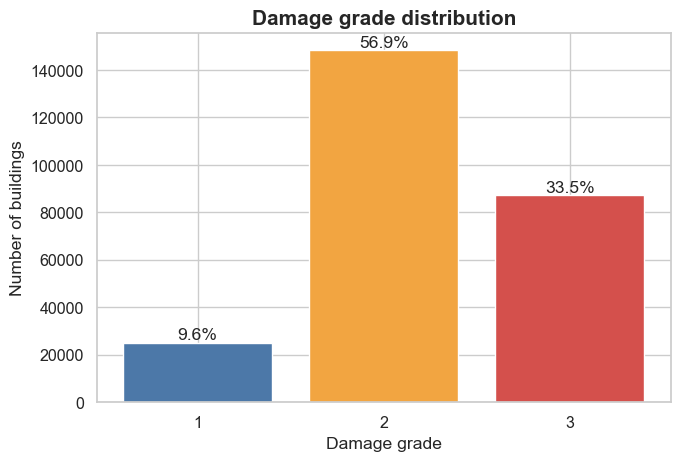

,count,percentage
damage_grade,,
1,25124,0.096408
2,148259,0.568912
3,87218,0.334680


In [9]:
target_distribution = train_labels["damage_grade"].value_counts().reindex(DAMAGE_ORDER)
fig, ax = plt.subplots(figsize=(7.4, 4.8))
bars = ax.bar(target_distribution.index.astype(str), target_distribution.values, color=[GRADE_COLORS[g] for g in DAMAGE_ORDER])
for bar, count in zip(bars, target_distribution.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{count / len(train_labels):.1%}", ha="center", va="bottom")
ax.set_title("Damage grade distribution", fontsize=15, fontweight="bold")
ax.set_xlabel("Damage grade")
ax.set_ylabel("Number of buildings")
save_plot("01_target_distribution.png")
plt.show()
target_distribution.to_frame("count").assign(percentage=lambda x: x["count"] / x["count"].sum())

### 7.2 Grouped damage composition

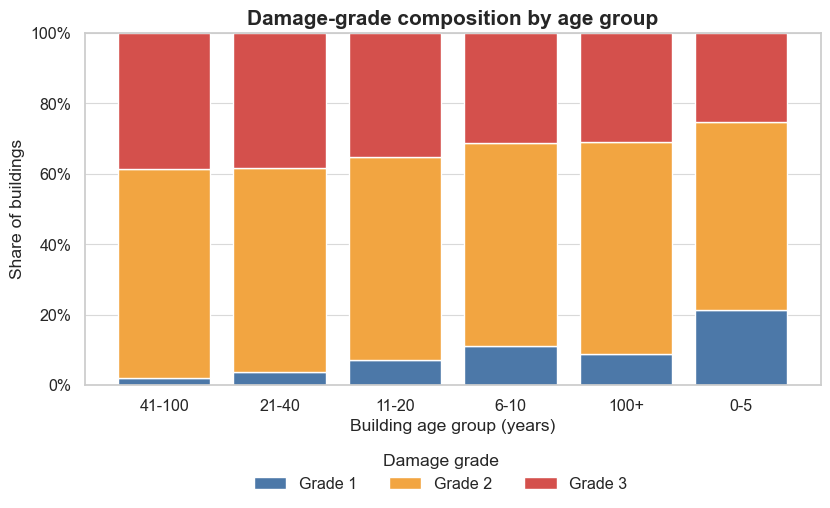

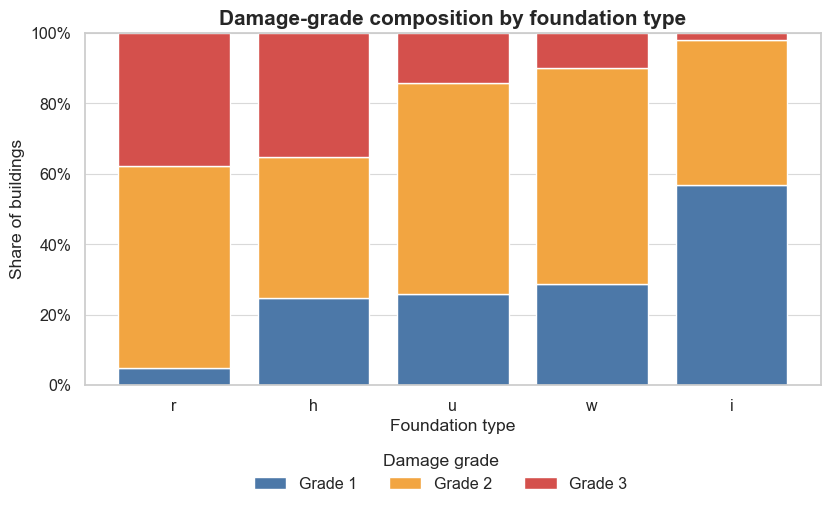

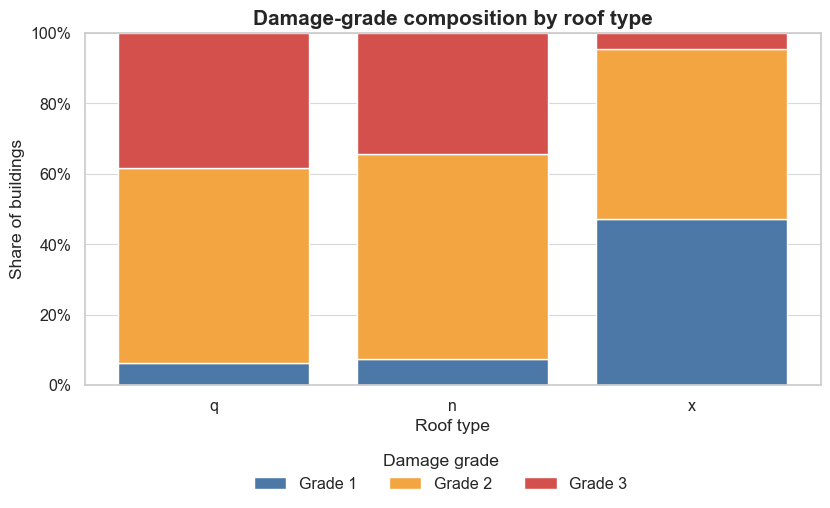

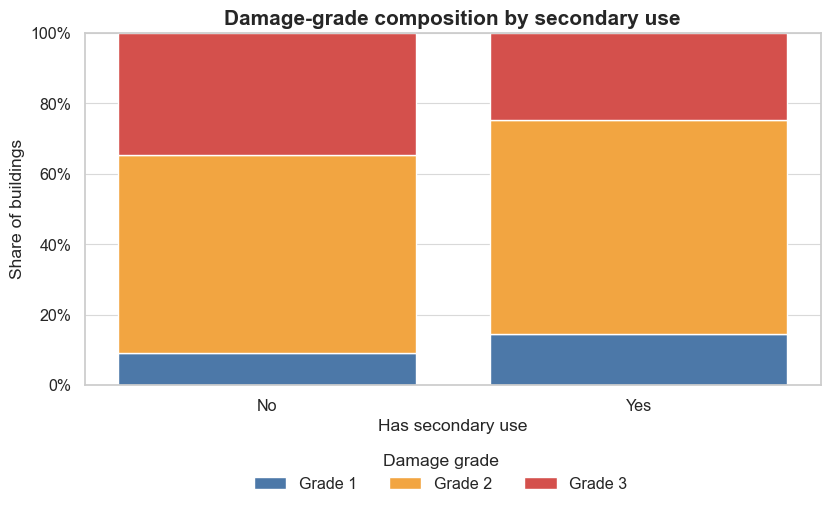

In [10]:
age_groups = pd.cut(labelled["age"], [-1, 5, 10, 20, 40, 100, np.inf], labels=["0-5", "6-10", "11-20", "21-40", "41-100", "100+"])
age_data = labelled.assign(age_group=age_groups)
age_mix = plot_damage_mix(age_data, "age_group", "Damage-grade composition by age group", "Building age group (years)", "02_age_groups_damage_mix.png")
foundation_mix = plot_damage_mix(labelled, "foundation_type", "Damage-grade composition by foundation type", "Foundation type", "03_foundation_damage_mix.png")
roof_mix = plot_damage_mix(labelled, "roof_type", "Damage-grade composition by roof type", "Roof type", "04_roof_type_damage_mix.png")
secondary_data = labelled.assign(secondary_use=labelled["has_secondary_use"].map({0: "No", 1: "Yes"}))
secondary_mix = plot_damage_mix(secondary_data, "secondary_use", "Damage-grade composition by secondary use", "Has secondary use", "05_secondary_use_damage_mix.png")

### 7.3 Numeric features by damage grade

c:\Users\Welkin\AppData\Local\anaconda3\envs\CS433\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\Welkin\AppData\Local\anaconda3\envs\CS433\lib\site-packages\seaborn\categorical.py:632: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
c:\Users\Welkin\AppData\Local\anaconda3\envs\CS433\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\Welkin\AppData\Local\anaconda3\envs\CS433\lib\site-packag

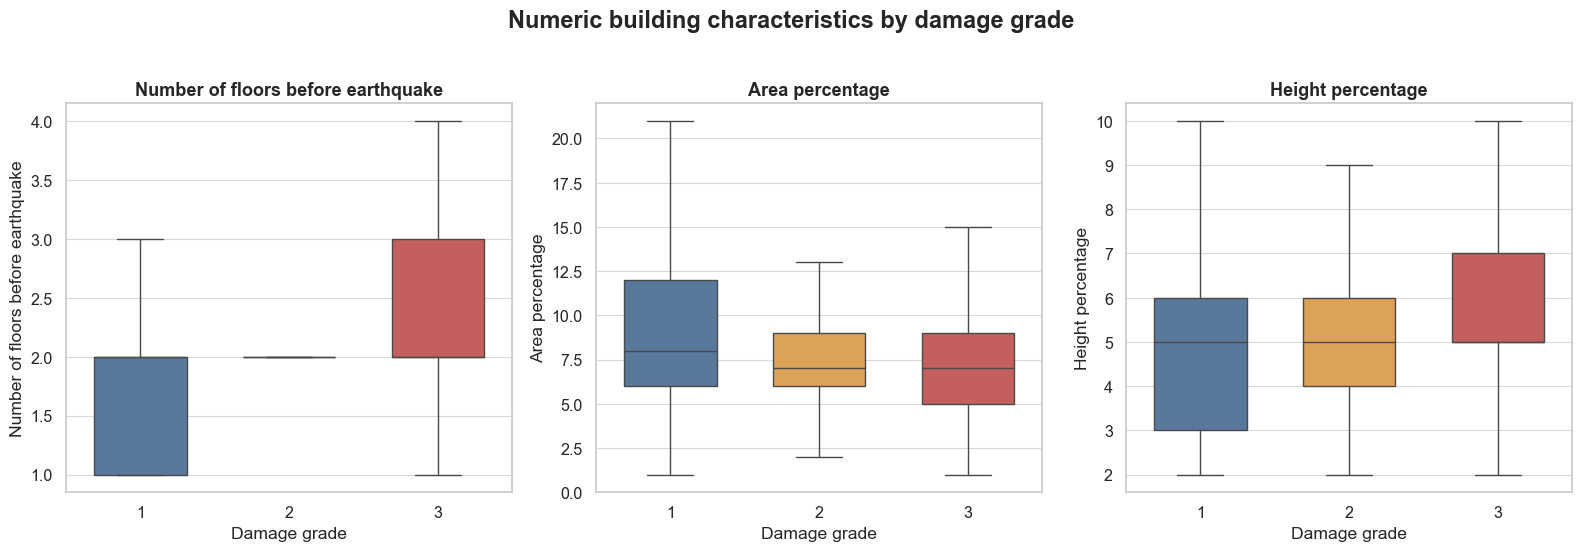

,count_floors_pre_eq,area_percentage,height_percentage
damage_grade,,,
1,2.0,8.0,5.0
2,2.0,7.0,5.0
3,2.0,7.0,5.0


In [11]:
numeric_views = [
    ("count_floors_pre_eq", "Number of floors before earthquake"),
    ("area_percentage", "Area percentage"),
    ("height_percentage", "Height percentage"),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.4))
for ax, (feature, label) in zip(axes, numeric_views):
    sns.boxplot(data=labelled, x="damage_grade", y=feature, hue="damage_grade",
                order=DAMAGE_ORDER, hue_order=DAMAGE_ORDER, dodge=False,
                palette=[GRADE_COLORS[g] for g in DAMAGE_ORDER], legend=False,
                showfliers=False, width=0.62, ax=ax)
    ax.set_title(label, fontsize=13, fontweight="bold")
    ax.set_xlabel("Damage grade")
    ax.set_ylabel(label)
    ax.grid(axis="y", color="#D9D9D9", linewidth=0.8)
    ax.set_axisbelow(True)
fig.suptitle("Numeric building characteristics by damage grade", fontsize=17, fontweight="bold", y=1.02)
fig.tight_layout()
save_plot("06_numeric_features_by_damage_grade_boxplots.png")
plt.show()
labelled.groupby("damage_grade")[[feature for feature, _ in numeric_views]].median()

## 8. Expanded exploratory data analysis

The following diagnostics add overall distributions, categorical frequency profiles, numeric relationships, material prevalence, and an additional grouped comparison. All chart labels are English and saved at 300 DPI.

### 8.1 Overall building-age distribution

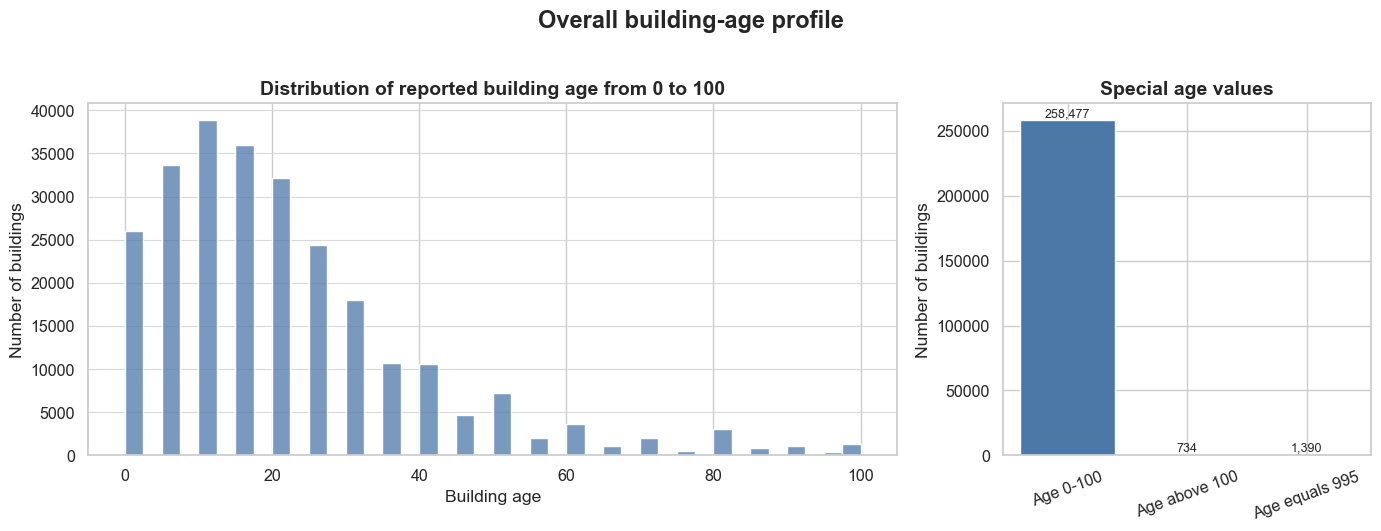

,count
Age 0-100,258477
Age above 100,734
Age equals 995,1390


In [12]:
age_under_101 = labelled.loc[labelled["age"] <= 100, "age"]
age_summary = pd.Series({
    "Age 0-100": int((labelled["age"] <= 100).sum()),
    "Age above 100": int(((labelled["age"] > 100) & (labelled["age"] != 995)).sum()),
    "Age equals 995": int((labelled["age"] == 995).sum()),
})
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [2.2, 1]})
sns.histplot(age_under_101, bins=40, color="#4C78A8", edgecolor="white", ax=axes[0])
axes[0].set_title("Distribution of reported building age from 0 to 100", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Building age")
axes[0].set_ylabel("Number of buildings")
axes[0].grid(axis="y", color="#D9D9D9", linewidth=0.8)
axes[0].set_axisbelow(True)
axes[1].bar(age_summary.index, age_summary.values, color=["#4C78A8", "#F2A541", "#D4504C"])
axes[1].set_title("Special age values", fontsize=14, fontweight="bold")
axes[1].set_ylabel("Number of buildings")
axes[1].tick_params(axis="x", rotation=20)
for index, value in enumerate(age_summary.values):
    axes[1].text(index, value, f"{value:,}", ha="center", va="bottom", fontsize=9)
fig.suptitle("Overall building-age profile", fontsize=17, fontweight="bold", y=1.02)
fig.tight_layout()
save_plot("07_overall_age_distribution.png")
plt.show()
age_summary.to_frame("count")

### 8.2 Overall distributions of key numeric variables

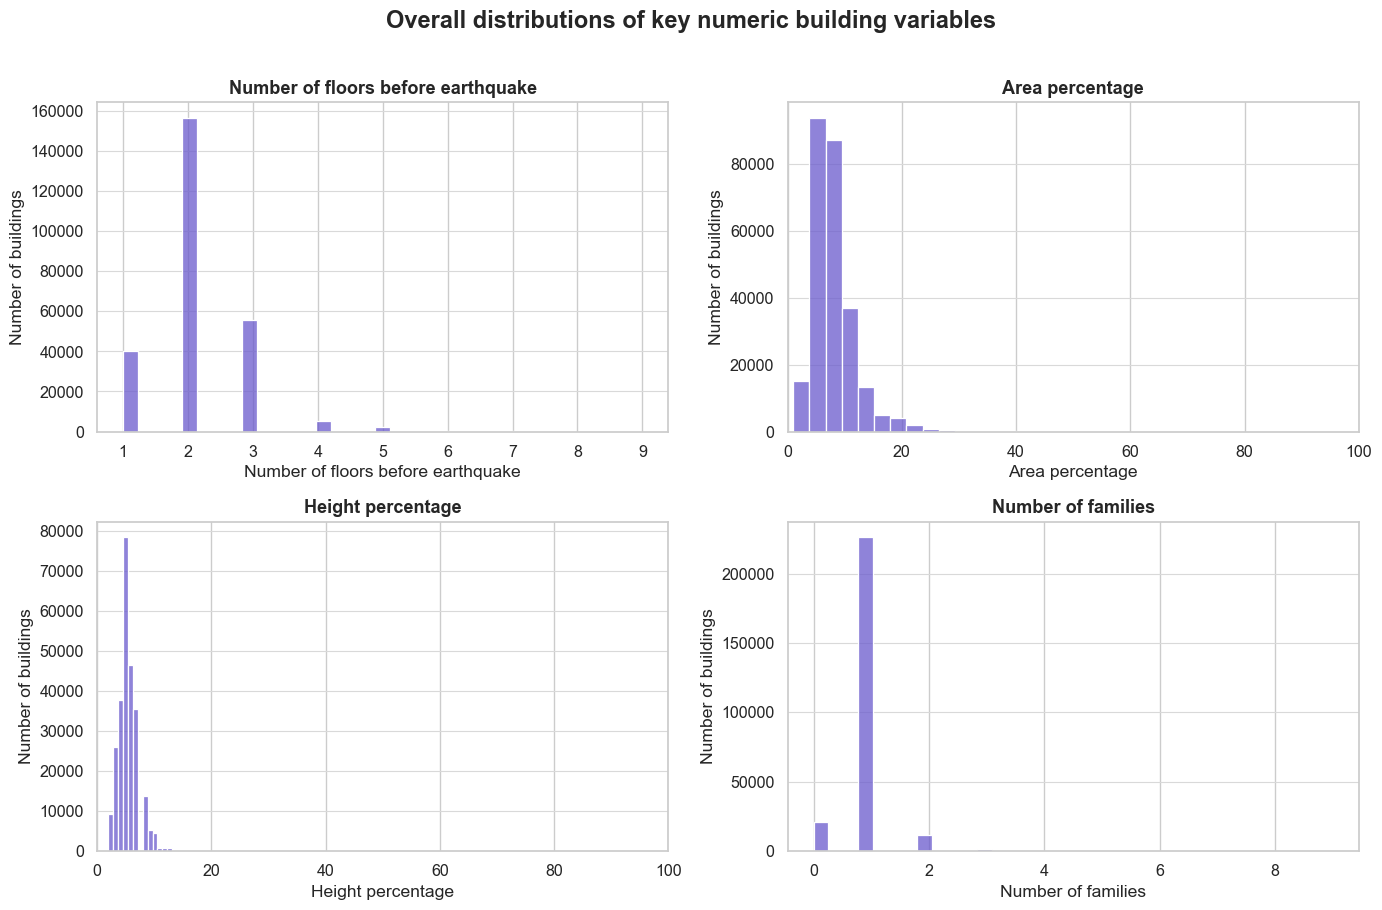

,count,mean,std,min,25%,50%,75%,max
count_floors_pre_eq,260601.0,2.129723,0.727665,1.0,2.0,2.0,2.0,9.0
area_percentage,260601.0,8.018051,4.392231,1.0,5.0,7.0,9.0,100.0
height_percentage,260601.0,5.434365,1.918418,2.0,4.0,5.0,6.0,32.0
count_families,260601.0,0.983949,0.418389,0.0,1.0,1.0,1.0,9.0


In [13]:
distribution_features = [
    ("count_floors_pre_eq", "Number of floors before earthquake", None),
    ("area_percentage", "Area percentage", (0, 100)),
    ("height_percentage", "Height percentage", (0, 100)),
    ("count_families", "Number of families", None),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (feature, title, xlim) in zip(axes.ravel(), distribution_features):
    sns.histplot(labelled[feature], bins=35, color="#6A5ACD", edgecolor="white", ax=ax)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel(title)
    ax.set_ylabel("Number of buildings")
    if xlim is not None:
        ax.set_xlim(*xlim)
    ax.grid(axis="y", color="#D9D9D9", linewidth=0.8)
    ax.set_axisbelow(True)
fig.suptitle("Overall distributions of key numeric building variables", fontsize=17, fontweight="bold", y=1.01)
fig.tight_layout()
save_plot("08_numeric_feature_distributions.png")
plt.show()
labelled[[feature for feature, _, _ in distribution_features]].describe().T

### 8.3 Frequency distributions of important categorical variables

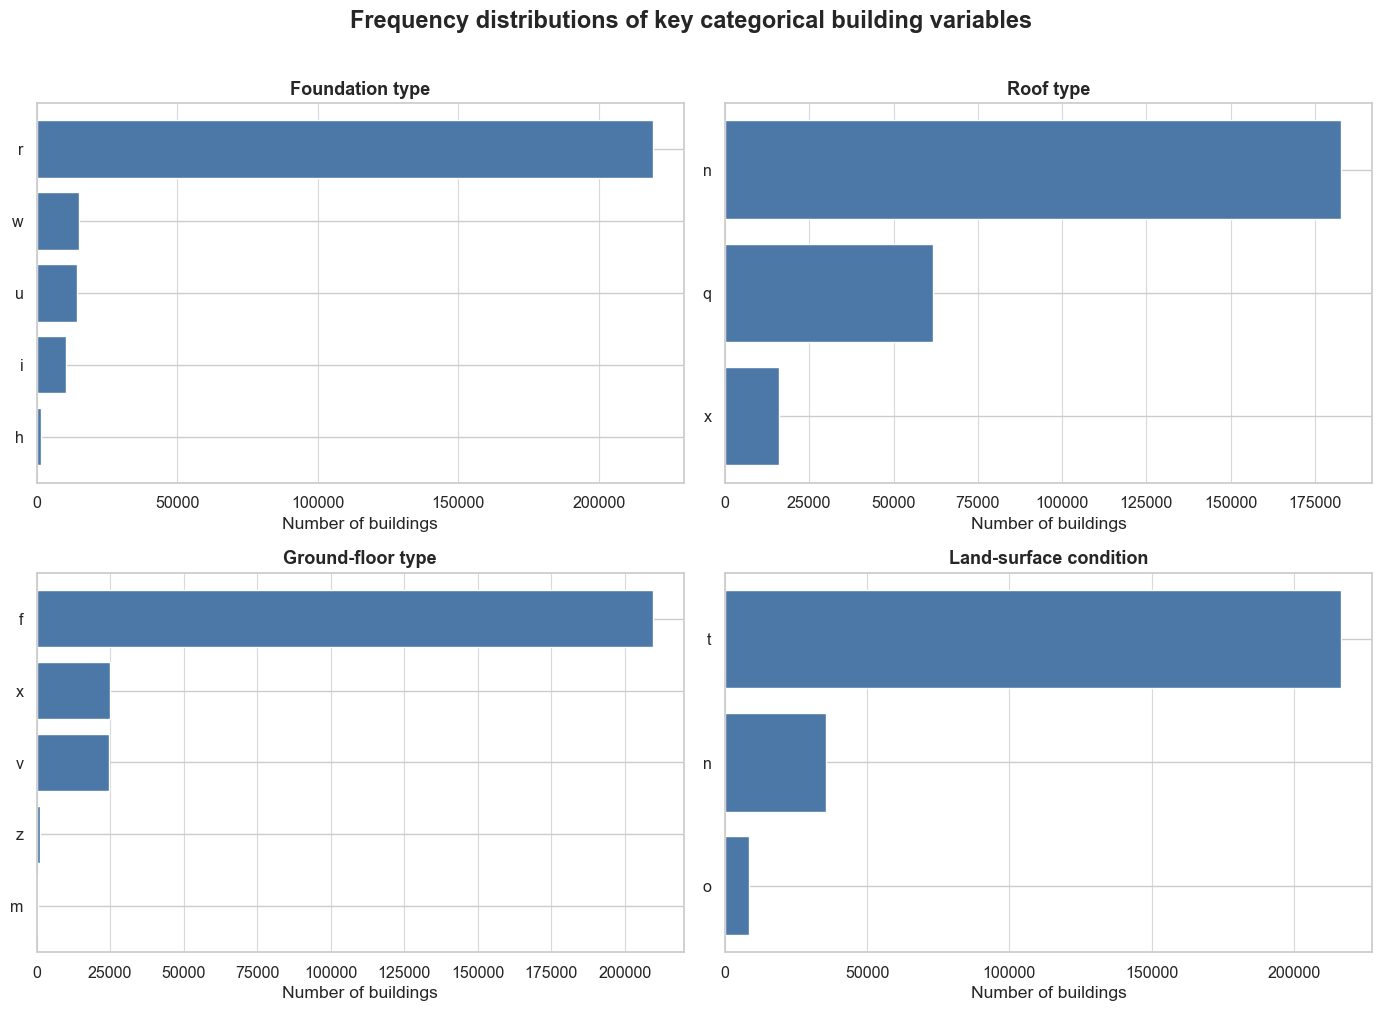

In [14]:
categorical_views = [
    ("foundation_type", "Foundation type"),
    ("roof_type", "Roof type"),
    ("ground_floor_type", "Ground-floor type"),
    ("land_surface_condition", "Land-surface condition"),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (feature, title) in zip(axes.ravel(), categorical_views):
    counts = labelled[feature].value_counts().sort_values()
    ax.barh(counts.index.astype(str), counts.values, color="#4C78A8")
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Number of buildings")
    ax.set_ylabel("")
    ax.grid(axis="x", color="#D9D9D9", linewidth=0.8)
    ax.set_axisbelow(True)
fig.suptitle("Frequency distributions of key categorical building variables", fontsize=17, fontweight="bold", y=1.01)
fig.tight_layout()
save_plot("09_categorical_feature_frequencies.png")
plt.show()

### 8.4 Relationships among numeric and engineered variables

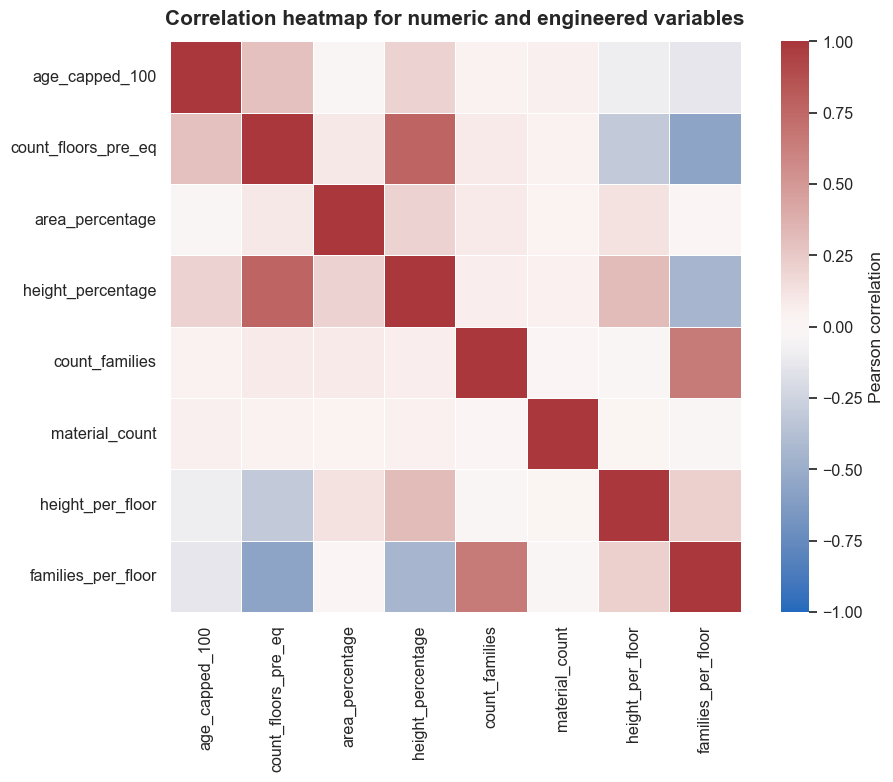

,age_capped_100,count_floors_pre_eq,area_percentage,height_percentage,count_families,material_count,height_per_floor,families_per_floor
age_capped_100,1.00,0.29,-0.03,0.20,0.04,0.06,-0.10,-0.14
count_floors_pre_eq,0.29,1.00,0.10,0.77,0.09,0.04,-0.31,-0.57
area_percentage,-0.03,0.10,1.00,0.20,0.09,0.03,0.13,0.01
height_percentage,0.20,0.77,0.20,1.00,0.06,0.05,0.31,-0.44
count_families,0.04,0.09,0.09,0.06,1.00,0.01,-0.02,0.65
material_count,0.06,0.04,0.03,0.05,0.01,1.00,0.02,-0.02
height_per_floor,-0.10,-0.31,0.13,0.31,-0.02,0.02,1.00,0.21
families_per_floor,-0.14,-0.57,0.01,-0.44,0.65,-0.02,0.21,1.00


In [15]:
correlation_columns = [
    "age_capped_100", "count_floors_pre_eq", "area_percentage",
    "height_percentage", "count_families", "material_count",
    "height_per_floor", "families_per_floor",
]
corr = labelled[correlation_columns].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation heatmap for numeric and engineered variables", fontsize=15, fontweight="bold", pad=12)
fig.tight_layout()
save_plot("10_numeric_feature_correlation_heatmap.png")
plt.show()
corr.round(2)

### 8.5 Material prevalence and observed severe damage rate

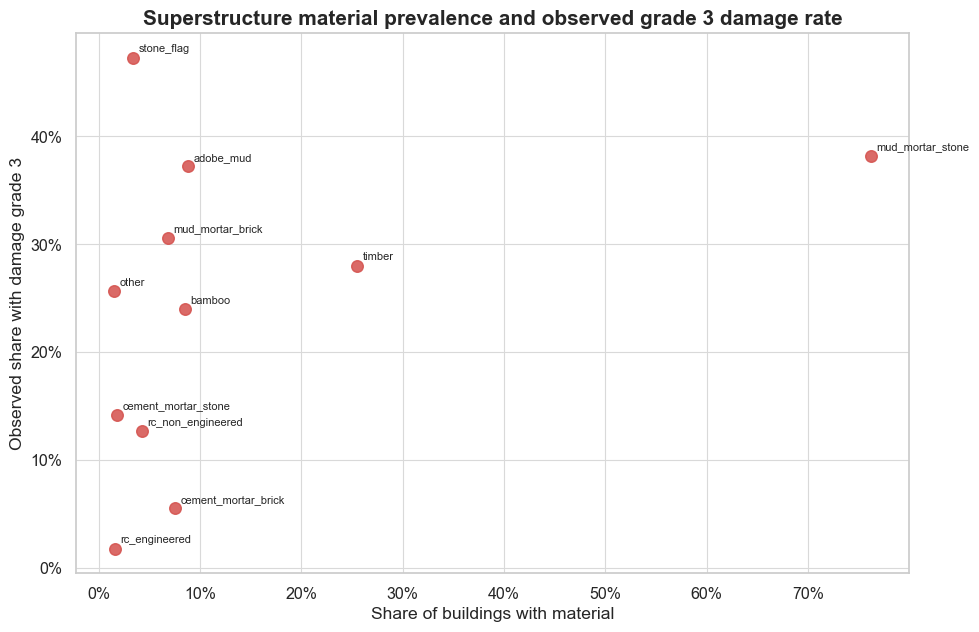

,material,prevalence,grade_3_rate,building_count
2,stone_flag,0.034332,0.472896,8947
1,mud_mortar_stone,0.761935,0.382019,198561
0,adobe_mud,0.088645,0.372495,23101
4,mud_mortar_brick,0.068154,0.306289,17761
6,timber,0.254988,0.280226,66450
10,other,0.014985,0.256338,3905
7,bamboo,0.085011,0.239866,22154
3,cement_mortar_stone,0.018235,0.142045,4752
8,rc_non_engineered,0.042590,0.127038,11099
5,cement_mortar_brick,0.075268,0.055519,19615


In [16]:
material_columns = [column for column in labelled.columns if column.startswith("has_superstructure_")]
material_summary = pd.DataFrame({
    "material": [column.replace("has_superstructure_", "") for column in material_columns],
    "prevalence": [float(labelled[column].mean()) for column in material_columns],
    "grade_3_rate": [float((labelled.loc[labelled[column] == 1, "damage_grade"] == 3).mean()) for column in material_columns],
    "building_count": [int(labelled[column].sum()) for column in material_columns],
}).query("building_count >= 500")
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.scatter(material_summary["prevalence"], material_summary["grade_3_rate"], s=70, color="#D4504C", alpha=0.85)
for _, row in material_summary.iterrows():
    ax.annotate(row["material"], (row["prevalence"], row["grade_3_rate"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_title("Superstructure material prevalence and observed grade 3 damage rate", fontsize=15, fontweight="bold")
ax.set_xlabel("Share of buildings with material")
ax.set_ylabel("Observed share with damage grade 3")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
ax.grid(color="#D9D9D9", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
save_plot("11_superstructure_prevalence_vs_damage.png")
plt.show()
material_summary.sort_values("grade_3_rate", ascending=False)

### 8.6 Damage-grade composition by number of floors

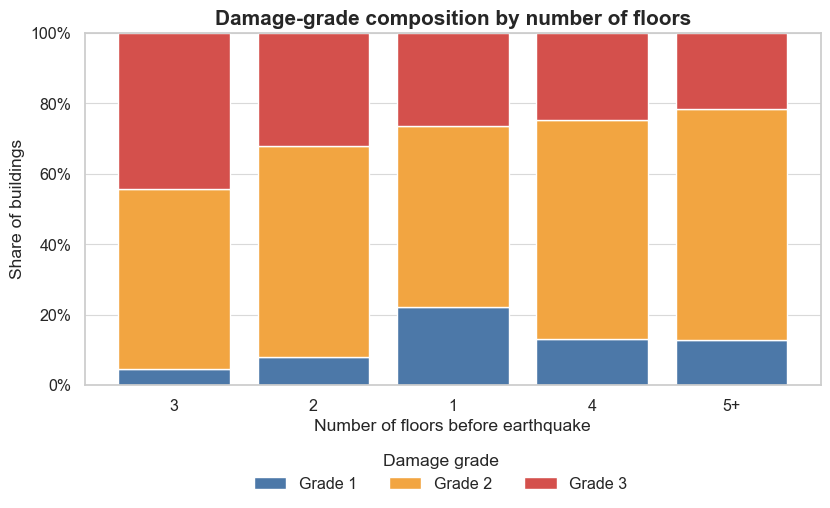

damage_grade,1,2,3
floor_group,,,
3,0.045616,0.512056,0.442329
2,0.080403,0.599963,0.319634
1,0.221780,0.514280,0.263940
4,0.130347,0.622050,0.247603
5+,0.127404,0.657051,0.215545


In [17]:
floor_data = labelled.assign(floor_group=labelled["count_floors_pre_eq"].clip(upper=5).astype(str).replace("5", "5+"))
floor_mix = plot_damage_mix(floor_data, "floor_group", "Damage-grade composition by number of floors", "Number of floors before earthquake", "12_floors_damage_mix.png")
floor_mix

### 8.7 Distributions of engineered per-floor variables

c:\Users\Welkin\AppData\Local\anaconda3\envs\CS433\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\Welkin\AppData\Local\anaconda3\envs\CS433\lib\site-packages\seaborn\categorical.py:632: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
c:\Users\Welkin\AppData\Local\anaconda3\envs\CS433\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\Welkin\AppData\Local\anaconda3\envs\CS433\lib\site-packag

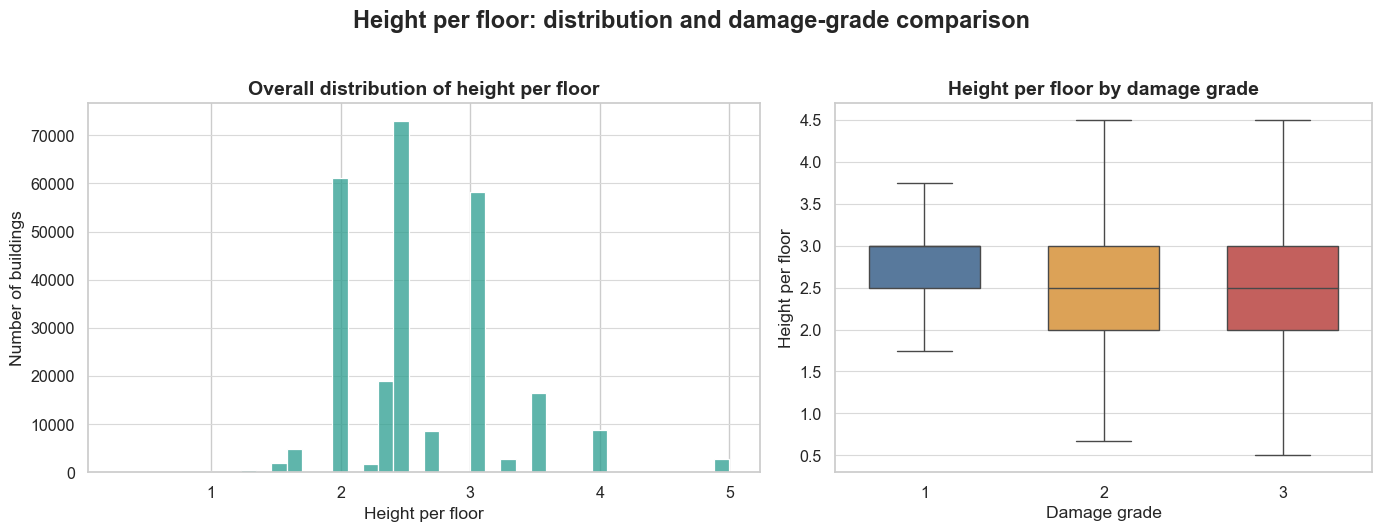

c:\Users\Welkin\AppData\Local\anaconda3\envs\CS433\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\Welkin\AppData\Local\anaconda3\envs\CS433\lib\site-packages\seaborn\categorical.py:632: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
c:\Users\Welkin\AppData\Local\anaconda3\envs\CS433\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\Welkin\AppData\Local\anaconda3\envs\CS433\lib\site-packag

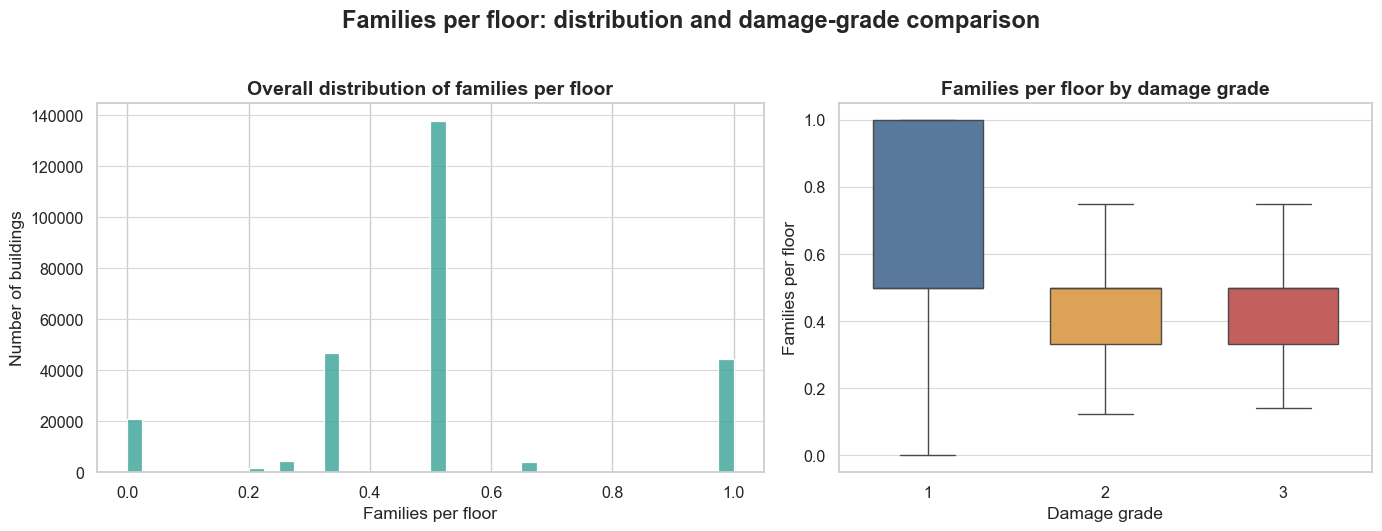

,count,mean,std,min,1%,50%,99%,max
height_per_floor,260601.0,2.618972,0.631865,0.285714,1.666667,2.5,5.0,32.0
families_per_floor,260601.0,0.518463,0.291683,0.000000,0.000000,0.5,1.0,9.0


In [18]:
derived_views = [
    ("height_per_floor", "Height per floor", "13_height_per_floor_distribution.png"),
    ("families_per_floor", "Families per floor", "14_families_per_floor_distribution.png"),
]
for feature, label, filename in derived_views:
    display_limit = labelled[feature].quantile(0.99)
    display_data = labelled[feature].clip(upper=display_limit)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})
    sns.histplot(display_data, bins=40, color="#2A9D8F", edgecolor="white", ax=axes[0])
    axes[0].set_title(f"Overall distribution of {label.lower()}", fontsize=14, fontweight="bold")
    axes[0].set_xlabel(label)
    axes[0].set_ylabel("Number of buildings")
    axes[0].grid(axis="y", color="#D9D9D9", linewidth=0.8)
    axes[0].set_axisbelow(True)
    box_data = labelled.assign(display_feature=display_data)
    sns.boxplot(data=box_data, x="damage_grade", y="display_feature", hue="damage_grade",
                order=DAMAGE_ORDER, hue_order=DAMAGE_ORDER, dodge=False,
                palette=[GRADE_COLORS[g] for g in DAMAGE_ORDER], legend=False,
                showfliers=False, width=0.62, ax=axes[1])
    axes[1].set_title(f"{label} by damage grade", fontsize=14, fontweight="bold")
    axes[1].set_xlabel("Damage grade")
    axes[1].set_ylabel(label)
    axes[1].grid(axis="y", color="#D9D9D9", linewidth=0.8)
    axes[1].set_axisbelow(True)
    fig.suptitle(f"{label}: distribution and damage-grade comparison", fontsize=17, fontweight="bold", y=1.02)
    fig.tight_layout()
    save_plot(filename)
    plt.show()

labelled[["height_per_floor", "families_per_floor"]].describe(percentiles=[0.01, 0.5, 0.99]).T

## 9. Expanded EDA takeaways

- The overall age chart distinguishes the realistic 0-100 distribution from the special 995 code, preventing the abnormal code from distorting the histogram.
- Histograms expose skew and concentration in floors, area, height, and family count; this supports the later choice of tree models or robust scaling.
- Categorical frequency charts reveal rare categories, which should be reviewed before one-hot encoding.
- The correlation heatmap helps identify redundant engineered numeric features; it is descriptive and does not decide feature removal by itself.
- Material prevalence versus observed grade-3 rate separates rare-but-high-risk material signals from common materials.
- The floor-count composition chart adds another structural grouped comparison alongside age, foundation, roof, and secondary-use views.

## 8. Takeaways

- Grade 2 is the majority class, so micro-F1 alone should be complemented by macro-F1, a confusion matrix, and per-class recall.
- Foundation type, roof type, material indicators, and geographic category IDs show different observed grade-3 proportions and should be retained as candidate predictors. These are descriptive relationships, not causal claims.
- The engineered features provide transparent structural summaries and are safe to apply identically to train and test data.
- `building_id` remains available in every output for traceability and submission, but must be removed from the model feature matrix before fitting.
- For scikit-learn models, fit encoders and scalers only on `X_train`; CatBoost can consume categorical columns directly.